# JS09 – Klasifikasi: Praktikum 1
## k-Nearest Neighbors (kNN) pada Dataset Iris

**Tujuan praktikum**

1. Memahami cara kerja kNN sebagai algoritma klasifikasi berbasis jarak.
2. Melakukan eksplorasi data Iris dan memahami pemisahan antar kelas.
3. Menerapkan **standardisasi fitur** sebelum kNN.
4. Melatih model kNN dan mengevaluasi dengan **akurasi, confusion matrix, precision, recall, dan F1-score**.
5. Menganalisis pengaruh nilai **k** terhadap performa dan overfitting.

**Dataset:** `iris.csv` berisi 150 bunga Iris dengan 4 fitur numerik (panjang/lebar sepal dan petal dalam cm) serta label `species` dengan tiga kelas: `setosa`, `versicolor`, dan `virginica`.

> kNN tidak membangun persamaan model secara eksplisit. Saat prediksi, kNN mencari **k tetangga terdekat** dari data latih dan memilih kelas dengan suara terbanyak. Karena berbasis jarak, skala fitur sangat memengaruhi hasil.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membaca data

In [2]:
data = pd.read_csv("iris.csv")

print("Ukuran data:", data.shape)
data.head()

Ukuran data: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 2. Eksplorasi data

Tahap ini memeriksa tipe data, statistik deskriptif, keseimbangan kelas, serta ada tidaknya nilai kosong dan duplikat.

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [5]:
data["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [6]:
print("Jumlah nilai kosong per kolom:")
print(data.isna().sum())
print("\nJumlah baris duplikat:", data.duplicated().sum())

Jumlah nilai kosong per kolom:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Jumlah baris duplikat: 1


### 3. Visualisasi data

Pairplot memperlihatkan sebaran setiap pasangan fitur. Warna menunjukkan kelas asli. Dari pola ini terlihat bahwa `setosa` mudah dipisahkan, sedangkan `versicolor` dan `virginica` sedikit tumpang tindih pada beberapa fitur.

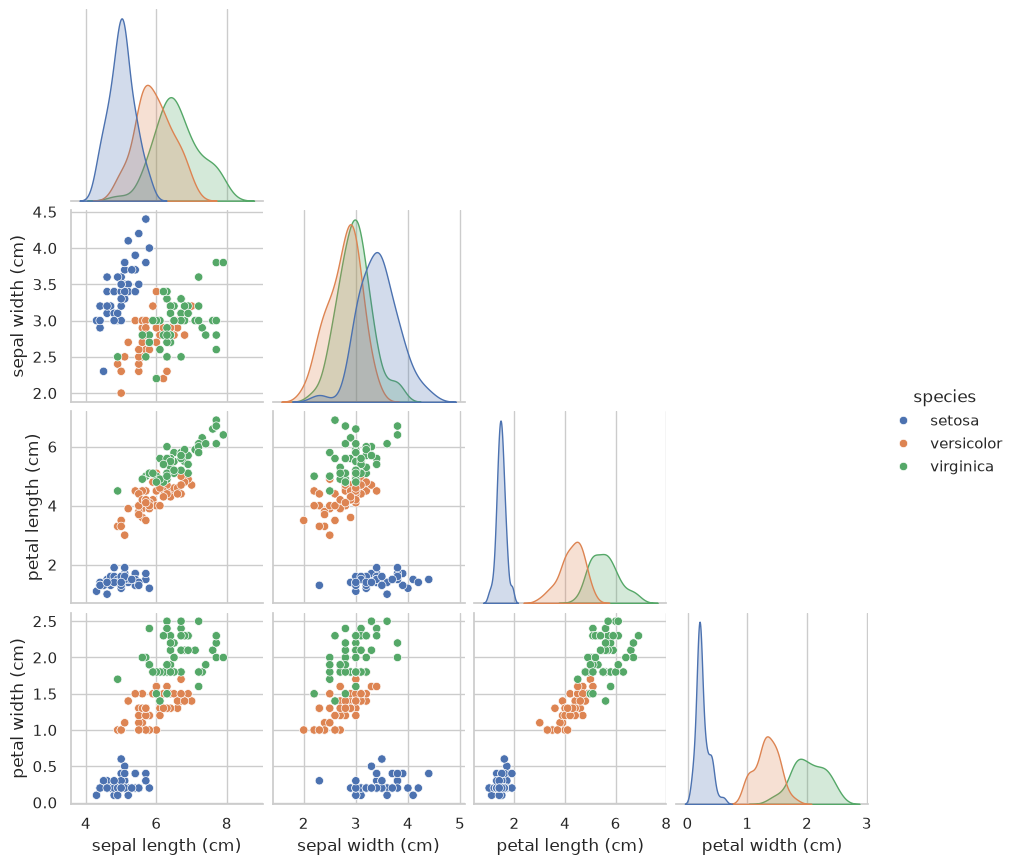

In [7]:
sns.pairplot(data, hue="species", corner=True, height=2.2)
plt.show()

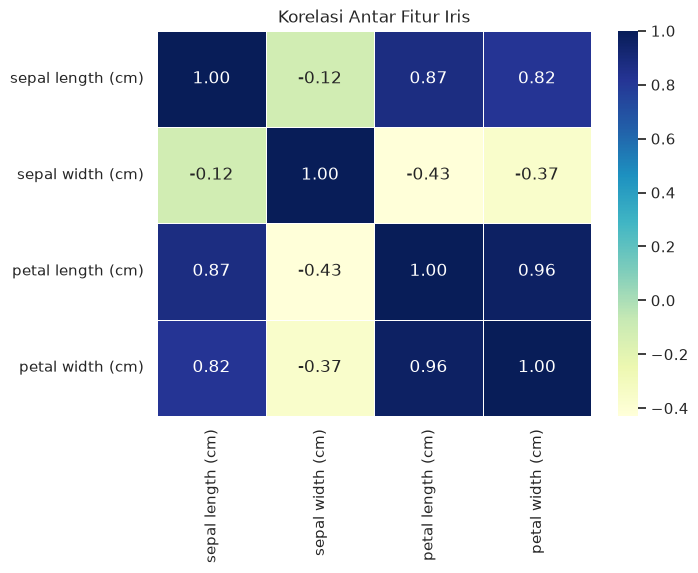

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
)
plt.title("Korelasi Antar Fitur Iris")
plt.show()

### 4. Preprocessing

Langkah preprocessing:

1. Pisahkan empat kolom fitur menjadi `X` dan kolom `species` menjadi `y`.
2. Bagi data menjadi **70% data latih** dan **30% data uji** dengan `random_state=42`.
3. Lakukan **standardisasi** dengan `StandardScaler`. Scaler hanya di-fit pada data latih, lalu digunakan untuk mentransformasi data uji agar tidak terjadi *data leakage*.

Standardisasi penting karena kNN menghitung jarak. Tanpa scaling, fitur dengan rentang lebih besar dapat mendominasi perhitungan jarak.

In [9]:
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Jumlah data latih :", X_train.shape[0])
print("Jumlah data uji   :", X_test.shape[0])
print("Dimensi fitur     :", X_train.shape[1])

Jumlah data latih : 105
Jumlah data uji   : 45
Dimensi fitur     : 4


### 5. Model kNN dengan k = 3

Model awal menggunakan `k=3`, nilai ganjil yang cukup kecil sehingga masih sensitif terhadap pola lokal tetapi tidak seekstrem `k=1`.

In [10]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("Akurasi data uji:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=knn.classes_))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, digits=3))

Akurasi data uji: 1.0

Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        19
  versicolor      1.000     1.000     1.000        13
   virginica      1.000     1.000     1.000        13

    accuracy                          1.000        45
   macro avg      1.000     1.000     1.000        45
weighted avg      1.000     1.000     1.000        45



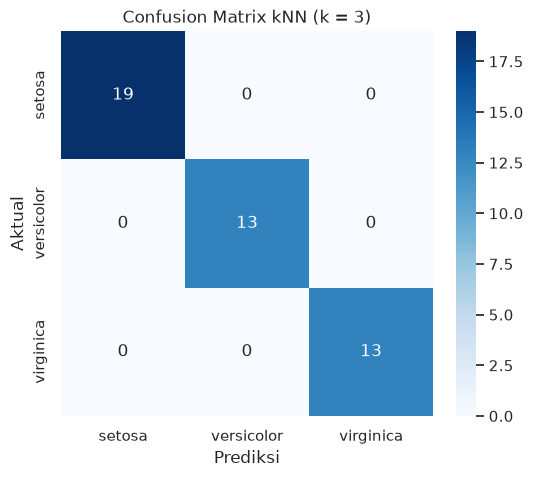

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=knn.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=knn.classes_,
    yticklabels=knn.classes_,
)
plt.title("Confusion Matrix kNN (k = 3)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

### 6. Analisis pengaruh nilai k

Nilai k menentukan seberapa banyak tetangga yang ikut memilih kelas:

- **k terlalu kecil** (misalnya 1) membuat model sangat fleksibel dan mudah menangkap noise → overfitting.
- **k terlalu besar** membuat batas keputusan terlalu halus dan dapat mengabaikan pola lokal → underfitting.

Kita membandingkan akurasi data latih, data uji, dan **5-fold cross-validation** pada data latih untuk k = 1 sampai 10.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hasil_k = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    train_acc = model.score(X_train_scaled, y_train)
    test_acc = model.score(X_test_scaled, y_test)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    cv_acc = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1
    ).mean()

    hasil_k.append({
        "k": k,
        "Akurasi latih": train_acc,
        "Akurasi uji": test_acc,
        "CV accuracy": cv_acc,
    })

hasil_k = pd.DataFrame(hasil_k)
hasil_k.round(4)

,k,Akurasi latih,Akurasi uji,CV accuracy
0,1,1.0000,0.9778,0.9143
1,2,0.9619,0.9778,0.9143
2,3,0.9429,1.0000,0.9238
3,4,0.9524,0.9778,0.9429
4,5,0.9524,1.0000,0.9333
5,6,0.9524,1.0000,0.9429
6,7,0.9429,1.0000,0.9048
7,8,0.9429,1.0000,0.9238
8,9,0.9429,1.0000,0.9238
9,10,0.9333,1.0000,0.9333


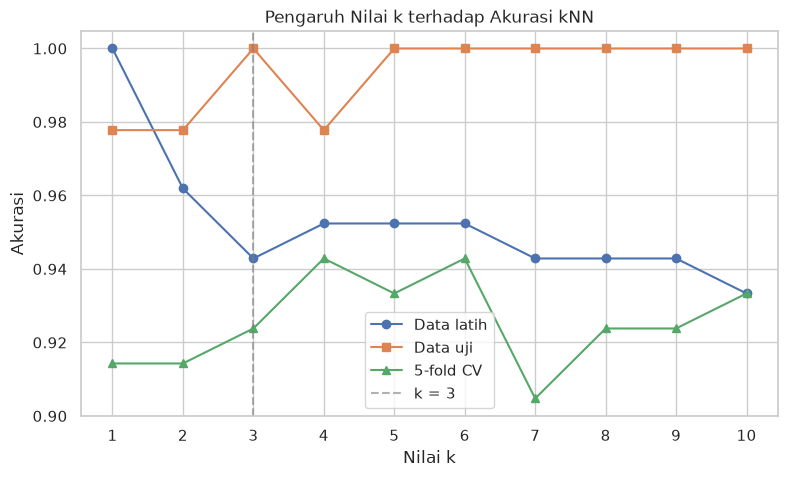

In [13]:
plt.figure(figsize=(9, 5))
plt.plot(hasil_k["k"], hasil_k["Akurasi latih"], marker="o", label="Data latih")
plt.plot(hasil_k["k"], hasil_k["Akurasi uji"], marker="s", label="Data uji")
plt.plot(hasil_k["k"], hasil_k["CV accuracy"], marker="^", label="5-fold CV")
plt.axvline(3, color="gray", linestyle="--", alpha=0.6, label="k = 3")
plt.title("Pengaruh Nilai k terhadap Akurasi kNN")
plt.xlabel("Nilai k")
plt.ylabel("Akurasi")
plt.xticks(range(1, 11))
plt.legend()
plt.show()

**Interpretasi kurva.** Pada `k=1`, akurasi data latih sempurna (1,0) tetapi akurasi data uji sedikit lebih rendah. Ini adalah gejala overfitting: model menghafal data latih. Seiring bertambahnya k, akurasi latih menurun karena batas keputusan menjadi lebih halus, sedangkan akurasi uji mencapai 1,0 pada `k=3` hingga `k=10`.

Cross-validation memberikan gambaran yang lebih stabil: nilai tertinggi berada pada `k=4` dan `k=6` (sekitar 0,943). Karena data Iris relatif mudah dan `k=3` sudah memberikan akurasi uji sempurna, `k=3` dipilih sebagai model final agar sesuai dengan alur praktikum dan tetap sederhana. `k=6` juga merupakan alternatif yang wajar jika kita mengutamakan stabilitas cross-validation.

### 7. Ilustrasi decision boundary

Untuk melihat efek k secara visual, kita gunakan dua fitur yang paling diskriminatif, yaitu **petal length** dan **petal width**. Model 2D ini hanya untuk ilustrasi, bukan model final yang memakai empat fitur.

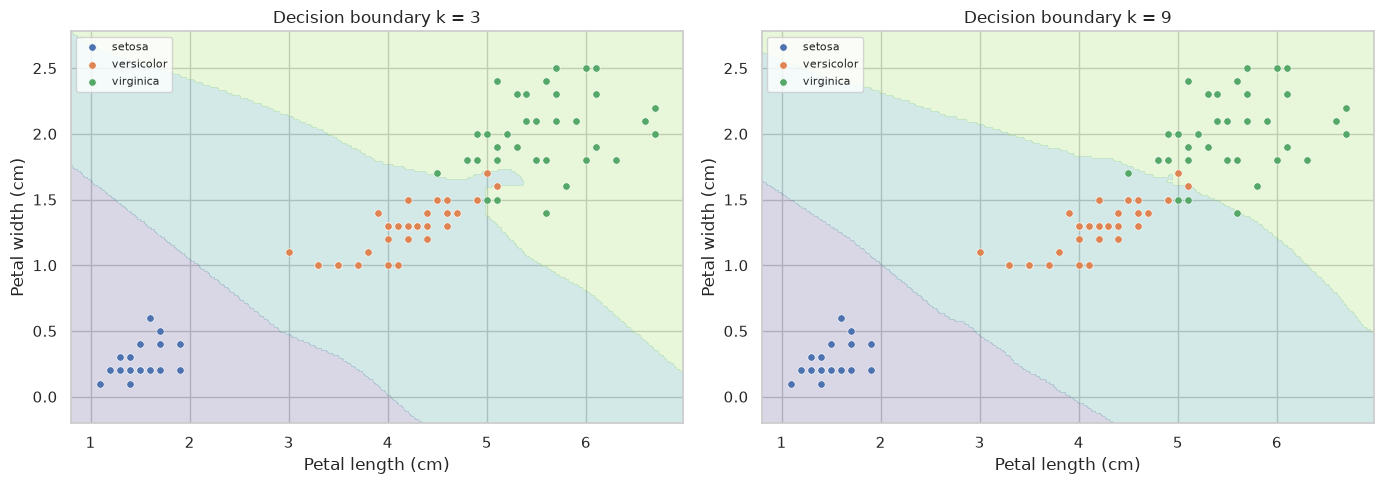

In [14]:
fitur_2d = ["petal length (cm)", "petal width (cm)"]
X2 = data[fitur_2d].to_numpy()
y2 = data["species"].to_numpy()

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.3, random_state=42
)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

label_order = sorted(np.unique(y2))
label_to_int = {label: i for i, label in enumerate(label_order)}

x_min, x_max = X2_train[:, 0].min() - 0.3, X2_train[:, 0].max() + 0.3
y_min, y_max = X2_train[:, 1].min() - 0.3, X2_train[:, 1].max() + 0.3
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for k, ax in zip([3, 9], axes):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X2_train_scaled, y2_train)

    grid_scaled = scaler2.transform(np.c_[xx.ravel(), yy.ravel()])
    Z = model.predict(grid_scaled).reshape(xx.shape)
    Z_num = pd.Categorical(Z.ravel(), categories=label_order).codes.reshape(xx.shape)
    ax.contourf(
        xx, yy, Z_num,
        levels=np.arange(len(label_order) + 1) - 0.5,
        alpha=0.20,
        cmap="viridis",
    )

    for label in label_order:
        mask = y2_train == label
        ax.scatter(
            X2_train[mask, 0],
            X2_train[mask, 1],
            s=28,
            label=label,
            edgecolor="white",
            linewidth=0.4,
        )

    ax.set_title(f"Decision boundary k = {k}")
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 8. Evaluasi model final dan interpretasi

Model final menggunakan empat fitur dan `k=3`. Confusion matrix menunjukkan seluruh 45 data uji terklasifikasi dengan benar: 19 `setosa`, 13 `versicolor`, dan 13 `virginica`.

**Mengapa hasilnya sempurna?**

- Dataset Iris memiliki pemisahan kelas yang cukup jelas, terutama `setosa`.
- Standardisasi membuat skala keempat fitur setara.
- `k=3` cukup kecil untuk menangkap pola lokal, tetapi tidak terlalu sensitif seperti `k=1`.

**Keterbatasan**

- Data uji hanya 45 baris; akurasi sempurna belum tentu bertahan pada data baru.
- Iris adalah dataset kecil dan “bersih”. Pada data dunia nyata, kNN bisa lebih sensitif terhadap outlier, fitur tidak relevan, dan perbedaan skala.
- kNN menyimpan seluruh data latih dan menghitung jarak saat prediksi, sehingga biaya prediksi lebih tinggi untuk dataset besar.
- Nilai k sebaiknya dipilih dengan validasi silang, bukan hanya dari satu split data uji.

**Kesimpulan**

1. kNN dengan `k=3` dan standardisasi mencapai akurasi **1,0** pada data uji Iris.
2. `k=1` menunjukkan overfitting (akurasi latih 1,0, uji lebih rendah).
3. Cross-validation menunjukkan `k=4` dan `k=6` sedikit lebih stabil, tetapi perbedaannya sangat kecil pada dataset ini.
4. Standardisasi dan pemilihan k yang wajar adalah dua faktor penting agar kNN bekerja baik.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS09 – Klasifikasi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi
- Müller, A. C., & Guido, S. (2016). *Introduction to Machine Learning with Python*. O'Reilly.
- `scikit-learn` – Nearest Neighbors. https://scikit-learn.org/stable/modules/neighbors.html
- `scikit-learn` – Preprocessing: StandardScaler. https://scikit-learn.org/stable/modules/preprocessing.html